[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/danpele/Blockchain-Applications/blob/main/Quantlets/L7/BA_L7_snoop/BA_L7_snoop.ipynb)

# BA_L7_snoop: 810 trading rules: data snooping

*Quantlet of Lecture 7, Blockchain Applications. Daniel Traian Pele, Bucharest University of Economic Studies.*

Data snooping with 810 moving-average and momentum rules on Bitcoin: Sharpe ratios in the selection period (2018-2022) against the evaluation period (2023 - 23 October 2026), the deflated Sharpe ratio, a permutation null of the best rule and White's reality check with a stationary bootstrap. EODHD daily Bitcoin prices.

In [1]:
OUT_DIR = '.'
SAVE_TO_DRIVE = False

In [2]:
import os
import tempfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 30)

# Chart style: transparent background, legend below the plot, no grey
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'font.size': 11, 'axes.labelsize': 12, 'axes.titlesize': 12,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.linewidth': 0.6, 'lines.linewidth': 1.3,
    'legend.facecolor': 'none', 'legend.framealpha': 0, 'legend.fontsize': 10,
})

# Chart colours (the same as in the slides)
BTC, ETH, BLUE, GOLD, RED, GREEN = '#E8913A', '#9B59B6', '#1A3A6E', '#B5853F', '#CD0000', '#2E7D32'
ORANGE, PURPLE, NAVY, TEAL = '#E67E22', '#8E44AD', '#1F2A44', '#17A2B8'

# outputs go to OUT_DIR (Google Drive) if SAVE_TO_DRIVE = True, otherwise to a temporary folder
OUT_PATH = OUT_DIR if globals().get('SAVE_TO_DRIVE') else tempfile.gettempdir()


def save_fig(fig, name):
    """Save the figure as PDF and PNG in OUT_PATH, then show it."""
    fig.savefig(os.path.join(OUT_PATH, f'{name}.pdf'), bbox_inches='tight')
    fig.savefig(os.path.join(OUT_PATH, f'{name}.png'), bbox_inches='tight', dpi=150)
    plt.show()
    plt.close(fig)


def legend_below(fig, ncol=3, bottom=0.08):
    """One legend for the whole figure, outside the plot, bottom centre (bottom = share of the height kept for it)."""
    h, l = [], []
    for ax in fig.axes:
        hh, ll = ax.get_legend_handles_labels()
        h += hh; l += ll
    fig.legend(h, l, loc='lower center', ncol=ncol, frameon=False)
    fig.tight_layout(rect=(0, bottom, 1, 1))

In [3]:
# Course data: the local copy if the notebook runs inside the repository, otherwise GitHub
REPO_RAW = 'https://raw.githubusercontent.com/danpele/Blockchain-Applications/main/data/'
DATA_DIR = next((os.path.join(d, 'data') for d in ('.', '..', '../..', '../../..') if os.path.isdir(os.path.join(d, 'data', 'market'))), '')


def data_file(sub, name):
    """Path or URL of data/<sub>/<name>."""
    return os.path.join(DATA_DIR, sub, name) if DATA_DIR else REPO_RAW + f'{sub}/{name}'


def daily(sym, end=None):
    """Daily closes from EODHD (data/market/<sym>.csv), positive prices only."""
    p = pd.read_csv(data_file('market', f'{sym}.csv'), parse_dates=['date']).set_index('date')['close']
    p = p[p > 0]
    return p.loc[:end] if end else p


def hourly(sym):
    """Hourly closes from EODHD (data/hourly/<sym>_1h.csv), indexed by UTC time."""
    x = pd.read_csv(data_file('hourly', f'{sym}_1h.csv'))
    x.index = pd.to_datetime(x['timestamp'], unit='s')
    return x['close']


def onchain(name):
    """Daily on-chain series (data/onchain/Crypto_<name>_20251008.csv), one column per coin."""
    return pd.read_csv(data_file('onchain', f'Crypto_{name}_20251008.csv'), na_values='NA', parse_dates=['date']).set_index('date')

Left: the Sharpe ratio of each rule in the selection period against the evaluation period, with the best in-sample rule in red and buy-and-hold
in 2023–2026 as a dashed line. Right: the maximum in-sample Sharpe ratio over all 810 rules when the returns are permuted, against the winner on the actual data.
**How to read it**: the in-sample winner falls back to the crowd out of sample; once the search is counted, its Sharpe ratio is not exceptional.

In [4]:
# the slide charts use 10-point text and an 8-point legend
plt.rcParams.update({'font.size': 10, 'axes.labelsize': 10, 'axes.titlesize': 10})
SLIDE_GOLD = '#B8860B'

END = pd.Timestamp('2026-10-23')                       # last day of the lecture sample
btc = pd.read_csv(data_file('market', 'BTC-USD.CC.csv'), parse_dates=['date']).set_index('date').loc[:END]
r = (100 * np.log(btc['close'])).diff().dropna().loc['2015-01-01':]           # daily log return, %
lv = np.log(btc['volume'].replace(0, np.nan)).diff().reindex(r.index).fillna(0)  # daily change of log volume
print(f'Bitcoin daily log returns: {len(r)} days, {r.index[0].date()} to {r.index[-1].date()}')

Bitcoin daily log returns: 4314 days, 2015-01-01 to 2026-10-23


## Data and method

Daily Bitcoin closes from EODHD (course repository, `data/market`), to 23 October 2026; daily log returns in per cent.

810 trading rules: 560 moving-average crossovers MA($s$, $l$) (long when the $s$-day average of the log price is above the $l$-day average) and
250 momentum rules MOM($k$) (long when the price is above its level $k$ days ago); the position for day $t$ is decided at the close of $t-1$,
with a cost of 10 basis points per change of position. Rules are selected on 2018–2022 and evaluated on 2023 – 23 October 2026.
The annualised Sharpe ratio (SR) of daily net returns $g_t$ is $\sqrt{365}\,\bar g / s_g$.

If we test $N$ rules with no skill, the best one still has a high SR. For $N$ independent rules with true SR $= 0$, the expected maximum is approximately
(SR in daily units, annualised SR divided by $\sqrt{365}$)

$$ \mathrm{SR}_0 = \sqrt{V[\widehat{\mathrm{SR}}_n]}\left[(1-\gamma)\,\Phi^{-1}\!\left(1 - \tfrac1N\right) + \gamma\, \Phi^{-1}\!\left(1 - \tfrac{1}{N e}\right)\right], \quad \gamma \approx 0.5772 . $$

The **probabilistic Sharpe ratio (PSR)** is the probability that the true SR exceeds a benchmark $\mathrm{SR}^*$, allowing for the skewness
$\hat\gamma_3$ and kurtosis $\hat\gamma_4$ of $T$ daily returns:

$$ \mathrm{PSR}(\mathrm{SR}^*) = \Phi\!\left(\frac{(\widehat{\mathrm{SR}} - \mathrm{SR}^*)\sqrt{T-1}}{\sqrt{1 - \hat\gamma_3 \widehat{\mathrm{SR}} + \frac{\hat\gamma_4 - 1}{4}\widehat{\mathrm{SR}}^2}}\right) . $$

The **deflated Sharpe ratio (DSR)** $= \mathrm{PSR}(\mathrm{SR}_0)$ (Bailey and López de Prado, 2014). Two null distributions of the best in-sample SR:

* permutation illustration: 200 random permutations of the selection-period returns (they destroy any predictability, and also volatility clustering);
* White's (2000) reality check: 1,000 stationary-bootstrap samples (random blocks, mean length 20 days) of the daily net returns of all rules;
  the null distribution is that of $\max_k (\mathrm{SR}^*_k - \widehat{\mathrm{SR}}_k)$.

The computation takes about two minutes.

In [5]:
from scipy import stats

COST = 0.10                                    # % per change of position (10 basis points)
S0, S1 = pd.Timestamp('2018-01-01'), pd.Timestamp('2022-12-31')
lc = np.log(btc['close'].loc['2016-01-01':END])
ret = 100 * lc.diff()
rules = [('MA', s_, l_) for s_ in range(2, 51, 2) for l_ in range(10, 251, 10) if l_ > s_ + 4] + [('MOM', k, 0) for k in range(1, 251)]


def signals(lcs):
    """Positions (1 = long, 0 = cash) of all rules; the position for day t is decided at the close of t-1."""
    ma = {w: lcs.rolling(w).mean() for w in set([x[1] for x in rules if x[0] == 'MA'] + [x[2] for x in rules if x[0] == 'MA'])}
    out = {}
    for typ, a_, b_ in rules:
        sig = (ma[a_] > ma[b_]) if typ == 'MA' else (lcs - lcs.shift(a_) > 0)
        out[(typ, a_, b_)] = sig.astype(float).shift(1)
    return pd.DataFrame(out)


def sharpe_mat(sig, rr):
    """Annualised Sharpe ratios and daily net returns (after costs) of all rules."""
    pos = sig.values
    g = pos * rr.values[:, None] - COST * np.abs(np.diff(np.vstack([np.zeros((1, pos.shape[1])), pos]), axis=0))
    return g.mean(0) / g.std(0, ddof=1) * np.sqrt(365), g


SIG = signals(lc)
isel, osel = (ret.index >= S0) & (ret.index <= S1), (ret.index > S1) & (ret.index <= END)
SR_in, G_in = sharpe_mat(SIG[isel].fillna(0), ret[isel])
SR_out, _ = sharpe_mat(SIG[osel].fillna(0), ret[osel])
best = int(np.nanargmax(SR_in))
bh_in = ret[isel].mean() / ret[isel].std() * np.sqrt(365)
bh_out = ret[osel].mean() / ret[osel].std() * np.sqrt(365)

# deflated Sharpe ratio, daily units
g = G_in[:, best]; T = len(g)
sr = g.mean() / g.std(ddof=1)
g3, g4 = stats.skew(g), stats.kurtosis(g, fisher=False)
Ntr, EM = len(rules), 0.5772156649
sr0 = np.sqrt(np.var(SR_in / np.sqrt(365), ddof=1)) * ((1 - EM) * stats.norm.ppf(1 - 1 / Ntr) + EM * stats.norm.ppf(1 - 1 / (Ntr * np.e)))
den = np.sqrt(1 - g3 * sr + (g4 - 1) / 4 * sr ** 2)
dsr = stats.norm.cdf((sr - sr0) * np.sqrt(T - 1) / den)
psr = stats.norm.cdf(sr * np.sqrt(T - 1) / den)

# permutation illustration: maximum in-sample SR over all rules when the selection-period returns are permuted
rng = np.random.default_rng(3)
mx = []
rv = ret.fillna(0).values.copy()
pos_in = np.where(isel)[0]
for b in range(200):
    rb = rv.copy(); rb[pos_in] = rng.permutation(rv[pos_in])
    lcb = pd.Series(lc.iloc[0] + np.cumsum(rb / 100), index=ret.index)
    srb, _ = sharpe_mat(signals(lcb)[isel].fillna(0), pd.Series(rb[pos_in], index=ret.index[isel]))
    mx.append(np.nanmax(srb))
mx = np.array(mx)

# White's reality check: stationary bootstrap (mean block 20 days) of the panel of rule returns
rng2 = np.random.default_rng(11)
Tin = G_in.shape[0]
sr_hat = G_in.mean(0) / G_in.std(0, ddof=1) * np.sqrt(365)
rc = []
for b in range(1000):
    ix = np.empty(Tin, dtype=int); ix[0] = rng2.integers(Tin)
    jump = rng2.random(Tin) < 1 / 20
    newst = rng2.integers(Tin, size=Tin)
    for t_ in range(1, Tin):
        ix[t_] = newst[t_] if jump[t_] else (ix[t_ - 1] + 1) % Tin
    gb = G_in[ix]
    rc.append(np.nanmax(gb.mean(0) / gb.std(0, ddof=1) * np.sqrt(365) - sr_hat))
rc = np.array(rc)

## Key numbers and the chart

number of rules                                                  810
best rule in 2018-2022                                        MOM(2)
Sharpe ratio of the best rule, 2018-2022                        0.84
Sharpe ratio of buy-and-hold, 2018-2022                         0.04
Sharpe ratio of the best rule, 2023-2026                        0.45
Sharpe ratio of buy-and-hold, 2023-2026                          0.9
rank of the best rule in 2023-2026 (of 810)                      779
permutation null: mean of the best Sharpe ratio                 0.55
permutation null: 95th percentile of the best Sharpe ratio      0.93
permutation p-value of the winner                              0.095
White's reality check p-value                                   0.31
expected maximum Sharpe ratio by chance SR_0 (annualised)       0.58
PSR against zero                                                0.97
deflated Sharpe ratio DSR (N = 810)                             0.72


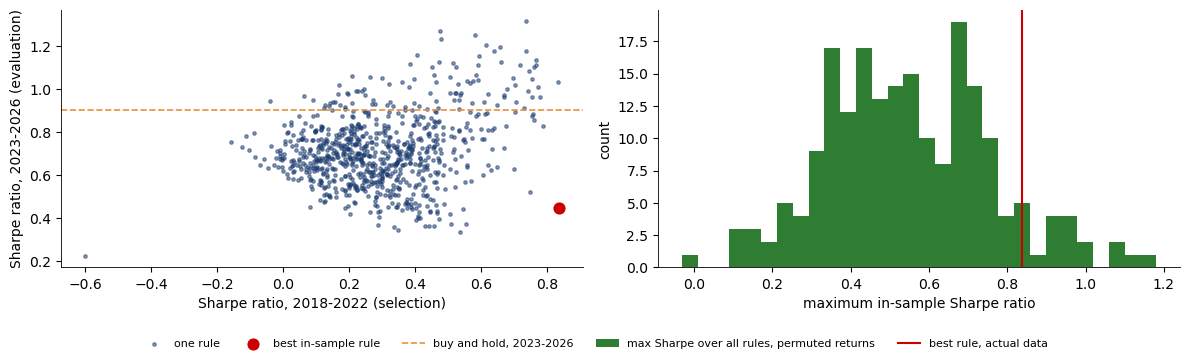

In [6]:
typ, a_, b_ = rules[best]
name = f'{typ}({a_}' + (f', {b_})' if typ == 'MA' else ')')
print(pd.Series({
    'number of rules': Ntr,
    'best rule in 2018-2022': name,
    'Sharpe ratio of the best rule, 2018-2022': round(SR_in[best], 2),
    'Sharpe ratio of buy-and-hold, 2018-2022': round(bh_in, 2),
    'Sharpe ratio of the best rule, 2023-2026': round(SR_out[best], 2),
    'Sharpe ratio of buy-and-hold, 2023-2026': round(bh_out, 2),
    'rank of the best rule in 2023-2026 (of 810)': int(stats.rankdata(-SR_out)[best]),
    'permutation null: mean of the best Sharpe ratio': round(mx.mean(), 2),
    'permutation null: 95th percentile of the best Sharpe ratio': round(np.quantile(mx, 0.95), 2),
    'permutation p-value of the winner': round((mx >= SR_in[best]).mean(), 3),
    "White's reality check p-value": round((rc >= SR_in[best]).mean(), 2),
    'expected maximum Sharpe ratio by chance SR_0 (annualised)': round(sr0 * np.sqrt(365), 2),
    'PSR against zero': round(psr, 2),
    'deflated Sharpe ratio DSR (N = 810)': round(dsr, 2),
}).to_string())

fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
ax[0].scatter(SR_in, SR_out, s=6, color=BLUE, alpha=0.5, label='one rule')
ax[0].scatter([SR_in[best]], [SR_out[best]], s=60, color=RED, zorder=5, label='best in-sample rule')
ax[0].axhline(bh_out, color=BTC, ls='--', lw=1.2, label='buy and hold, 2023-2026')
ax[0].set_xlabel('Sharpe ratio, 2018-2022 (selection)'); ax[0].set_ylabel('Sharpe ratio, 2023-2026 (evaluation)')
ax[1].hist(mx, bins=30, color=GREEN, label='max Sharpe over all rules, permuted returns')
ax[1].axvline(SR_in[best], color=RED, lw=1.5, label='best rule, actual data')
ax[1].set_xlabel('maximum in-sample Sharpe ratio'); ax[1].set_ylabel('count')
fig.legend(loc='lower center', ncol=5, frameon=False, fontsize=8)
fig.tight_layout(rect=(0, 0.08, 1, 1))
save_fig(fig, 'ba_l7_snoop')